In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values
from matplotlib import pyplot as plt

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
FIGUREDIR = DATADIR / 'publication' / 'Ext_Fig_09'
FIGUREDIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Load control anndata
fp_anndata = DATADIR / '9_objects' / 'singlecell' / 'hypomap3d_singlecell_control.h5ad'
scdata = sc.read_h5ad(fp_anndata)

### Subplot D: DotPlot

In [5]:
# normalize single cell anndata
sc.pp.normalize_total(scdata, target_sum=10_000)
sc.pp.log1p(scdata)

In [72]:
# Manually define markers of interest
MARKERS = {
    'Top': ['Tac1', 'Foxp1', 'Foxp2', 'Cd36', 'Pbx3'],
    # 'Top': ['Tac1', 'Adamts2', 'Nr4a2', 'Satb1', 'Cd36', 'Cubn'],
    'Dopa. Lepr+': ['Th', 'Ddc', 'Slc6a3', 'Lepr'],
    'Sister': ['Tll1', 'Crhbp', 'Ngfr', 'Acvr1c', 'Tacr3'],
}

In [68]:
# Subset to only candidates
SELECTION = ['Gl4-218', 'Gl4-220', 'Gl4-221']

SELECTION = sorted(SELECTION, key = lambda x: int(x.split('-')[1]))

scdata_subset = scdata[scdata.obs['L4_ID'].isin(SELECTION)].copy()
scdata_subset

AnnData object with n_obs × n_vars = 3007 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'log1p'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

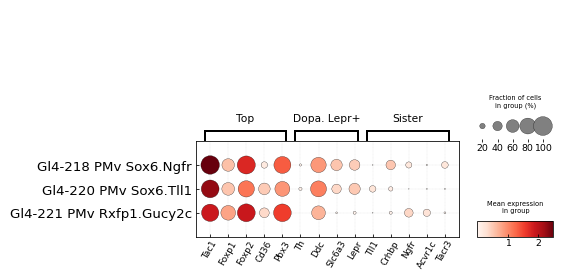

In [73]:
with plt.style.context('../../../resources/figures.mplstyle') as rc:

    plt.close('all') # a development trick
    fig, ax = plt.subplots(1, 1, figsize=(150*MM, 75*MM))
    dp = sc.pl.dotplot(
        scdata_subset, 
        MARKERS, 
        groupby='L4_descr', 
        cmap='Reds',
        dot_min=0.01,
        swap_axes=False,
        var_group_rotation=0,
        ax=ax,
        show=False,
        vmax=2.5,
    )

    main_ax = dp['mainplot_ax']


    main_ax.spines['top'].set_visible(True)
    main_ax.spines['right'].set_visible(True)

    main_ax.set_axisbelow(True)
    main_ax.grid(which='major', color='lightgrey', linestyle='--', linewidth=0.2)

    main_ax.set_xticklabels(main_ax.get_xticklabels(), rotation=60, ha='center', va='top')
    main_ax.tick_params(axis='y', pad=3, labelsize=10)

    if 'gene_group_ax' in dp:
        for text in dp['gene_group_ax'].texts:
            text.set_fontsize(8)
            text.set_rotation(0)
            text.set_ha('center')
            text.set_va('bottom')

    dp['size_legend_ax'].title.set_size(5)
    dp['size_legend_ax'].tick_params('x', labelsize=7)

    dp['color_legend_ax'].title.set_size(5)
    dp['color_legend_ax'].tick_params('x', labelsize=7)


    fig.tight_layout()
    # fig.subplots_adjust(top=1)
    fig.savefig(
        FIGUREDIR / "subplot_d_dotplot.pdf",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )

    plt.show()
    plt.close(fig)


### Exploratory analysis

In [64]:
# Load markers
markers_table = pd.read_csv('/REDACTED-path/HypoMap3D-data/v0.9/9_objects/markers/hypomap3d_cell_type_marker_genes_L4.csv')
markers_table['temp'] = markers_table['specificity'] * markers_table['pctA']

# Separate all vs sister marker tables
markers_table_vs_all = markers_table[markers_table['comparison'] == 'OneVsAll']
display(markers_table_vs_all.head(3))
markers_table_vs_sister = markers_table[markers_table['comparison'] == 'OneVsSisters']
display(markers_table_vs_sister.head(3))

,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
131374,L4,Gl4-290,Gl4-290 VMH Cobll1.Vgll2,Gl4-290 VMH Nr5a1 Acvr1c Glut_3c-1,OneVsAll,Vgll2,4.839992,0.331790,0.008448,0.494650,0.014537,5.092889,5.076782e-259,5.503232e-256,2.483233,2,1.605861
131375,L4,Gl4-290,Gl4-290 VMH Cobll1.Vgll2,Gl4-290 VMH Nr5a1 Acvr1c Glut_3c-1,OneVsAll,Ros1,4.832614,0.324074,0.011216,1.163156,0.032146,5.179119,1.854556e-245,2.010339e-242,3.228527,3,1.566125
131376,L4,Gl4-290,Gl4-290 VMH Cobll1.Vgll2,Gl4-290 VMH Nr5a1 Acvr1c Glut_3c-1,OneVsAll,Acp7,4.173989,0.106481,0.005094,0.136530,0.005718,4.593383,4.941978e-59,5.357104e-56,0.755680,81,0.444453


,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
0,L4,Gl4-5,Gl4-5 LM Prkch.Trabd2b,Gl4-5 PH-LHA Foxb1 E2f7 Glut_6-1,OneVsSisters,Pde1a,1.707604,0.346734,0.092391,0.998466,0.127722,2.948197,3.128246e-17,4.220004e-14,2.728597,7,0.592084
1,L4,Gl4-5,Gl4-5 LM Prkch.Trabd2b,Gl4-5 PH-LHA Foxb1 E2f7 Glut_6-1,OneVsSisters,Gm30003,1.515356,0.124372,0.025362,0.140916,0.027225,2.291704,1.991422e-10,2.686429e-07,1.547667,69,0.188468
2,L4,Gl4-5,Gl4-5 LM Prkch.Trabd2b,Gl4-5 PH-LHA Foxb1 E2f7 Glut_6-1,OneVsSisters,Rcn1,1.424873,0.194724,0.050725,0.217400,0.038800,2.428716,4.012977e-08,5.413506e-05,1.365786,34,0.277456


In [65]:
# Get summed (specificty * pctA) across all celltypes in SELECTION – to get top markers
scores = []
for celltype in SELECTION:
    mask = markers_table_vs_all['celltype_id'] == celltype
    subset = markers_table_vs_all.loc[mask, :]
    
    subset = subset.sort_values('rank')
    
    score = subset.set_index('gene_name')['temp']
    
    scores.append(
        score[score > 0.5]
    )
    
    display(subset.head(10))

sum(scores).sort_values(ascending=False).head(10)

,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
289891,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Irx5,4.735204,0.490251,0.014117,0.612679,0.018977,5.015987,0.0,0.0,5.284135,1,2.321437
289893,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Crnde,4.559538,0.506964,0.017281,0.660454,0.022454,4.881360,0.0,0.0,5.413396,2,2.311521
289885,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Gucy2c,6.020355,0.364903,0.004832,0.462561,0.006389,6.181936,0.0,0.0,4.129443,3,2.196843
289919,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Satb1,2.563104,0.846797,0.151977,3.412113,0.265520,3.684352,0.0,0.0,9.256150,4,2.170428
289890,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Irx3,5.046467,0.415042,0.010861,0.561166,0.014104,5.317687,0.0,0.0,4.289661,5,2.094494
289929,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Tac1,2.266057,0.892758,0.170602,8.746661,0.865876,3.336726,0.0,0.0,9.223525,6,2.023040
289892,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Cd36,4.655852,0.422006,0.013876,0.685973,0.021893,4.972438,0.0,0.0,4.703012,7,1.964795
289935,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Foxp2,2.082492,0.930362,0.171013,7.769475,0.957660,3.020488,0.0,0.0,10.201526,8,1.937471
289909,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Nr4a2,3.122412,0.601671,0.044896,1.486627,0.120525,3.625972,0.0,0.0,6.551642,9,1.878666
289905,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsAll,Lmx1a,3.390612,0.551532,0.034289,1.013577,0.070867,3.840152,0.0,0.0,5.852249,10,1.870031


,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
238082,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Rxfp1,5.173614,0.789474,0.024892,3.299754,0.072440,5.510487,0.000000e+00,0.000000e+00,7.629012,1,4.084432
238080,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Crnde,5.335219,0.651629,0.017444,1.110498,0.022493,5.628717,0.000000e+00,0.000000e+00,6.521572,2,3.476583
238078,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Irx3,5.923845,0.563910,0.010976,1.005126,0.014099,6.159025,0.000000e+00,0.000000e+00,6.286096,3,3.340514
238081,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Irx5,5.261704,0.586466,0.014304,0.877581,0.019114,5.524783,0.000000e+00,0.000000e+00,5.928822,4,3.085811
238075,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Lrat,7.962258,0.358396,0.001645,0.508225,0.001945,8.035687,0.000000e+00,0.000000e+00,4.479890,5,2.853642
238085,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Cpa6,4.718430,0.556391,0.027942,2.268910,0.061051,5.217402,1.155952e-273,2.002109e-270,4.360778,6,2.625292
238091,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Lmx1a,3.901114,0.646617,0.034498,1.437955,0.071083,4.340841,1.375164e-141,2.381784e-138,5.104158,7,2.522525
238087,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Lmx1b,4.171518,0.556391,0.025133,0.798648,0.033816,4.566213,9.315311e-139,1.613412e-135,5.116572,8,2.320995
238077,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Irx6,6.039104,0.383459,0.005115,0.440365,0.006013,6.202382,0.000000e+00,0.000000e+00,4.619270,9,2.315746
238112,L4,Gl4-222,Gl4-222 PMv Rxfp1.Lrat,Gl4-222 PMv-TMv Pitx2 Glut_5-2,OneVsAll,Cpne8,2.244143,0.929825,0.194259,4.608026,0.427931,3.429479,2.383200e-195,4.127703e-192,7.829594,11,2.086659


,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
176217,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Rxfp1,5.070112,0.601528,0.024524,3.164338,0.069892,5.501098,0.0,0.0,9.750724,1,3.049816
176214,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Ngfr,5.826512,0.505459,0.012279,1.340790,0.019337,6.116634,0.0,0.0,6.858970,2,2.945060
176222,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Crnde,4.689298,0.507642,0.017120,0.716337,0.022161,5.016635,0.0,0.0,7.490000,3,2.380484
176230,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Lmx1a,3.786422,0.615721,0.034023,1.313894,0.070105,4.229352,0.0,0.0,9.818909,4,2.331378
176221,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Irx5,4.763628,0.475983,0.013983,0.621611,0.018769,5.051977,0.0,0.0,7.255339,5,2.267404
176249,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Tac1,2.497253,0.894105,0.170364,10.967064,0.859944,3.672932,0.0,0.0,12.010399,6,2.232806
176228,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Lmx1b,3.983107,0.502183,0.024762,0.700429,0.033312,4.396279,0.0,0.0,7.809485,7,2.000250
176218,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Irx3,5.046488,0.396288,0.010758,0.558529,0.013929,5.328116,0.0,0.0,4.930871,8,1.999864
176252,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Satb1,2.394494,0.830786,0.151774,2.927568,0.265226,3.464939,0.0,0.0,11.802644,9,1.989312
176256,L4,Gl4-223,Gl4-223 PMv Rxfp1.Calca,Gl4-223 PMv-TMv Pitx2 Glut_5-3,OneVsAll,Cpne8,2.181298,0.882096,0.193704,4.507765,0.424514,3.408873,0.0,0.0,13.126981,10,1.924114


gene_name
Crnde            8.168589
Irx5             7.674652
Irx3             7.434872
Lmx1a            6.723934
Lmx1b            6.029431
Ngfr             5.444843
C130021I20Rik    4.584596
Irx6             4.170533
Pbx3             3.974059
Igsf11           3.218515
Name: temp, dtype: float64

In [66]:
sum(scores).sort_values(ascending=False).head(10).index.tolist()

['Crnde',
 'Irx5',
 'Irx3',
 'Lmx1a',
 'Lmx1b',
 'Ngfr',
 'C130021I20Rik',
 'Irx6',
 'Pbx3',
 'Igsf11']

In [69]:
for celltype in SELECTION:
    mask = markers_table_vs_sister['celltype_id'] == celltype
    subset = markers_table_vs_sister.loc[mask, :]
    
    subset = subset.sort_values('rank')
    
    score = subset.set_index('gene_name')['temp']

    display(subset.head(10))

,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
60179,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Cdh6,2.813087,0.461656,0.069841,1.040680,0.073548,3.815956,8.654835e-80,4.171630e-77,3.438712,1,1.298680
60178,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Ngfr,3.749860,0.233129,0.015420,0.383050,0.019329,4.281035,1.385786e-53,6.679486e-51,2.110434,2,0.874200
60180,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Tacr3,2.791363,0.259202,0.029478,0.397072,0.034590,3.507745,6.793302e-37,3.274372e-34,1.565902,4,0.723528
60184,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Crhbp,1.678331,0.406442,0.115193,1.459071,0.181373,3.005934,5.855760e-64,2.822476e-61,3.245548,5,0.682144
60195,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Ap1s2,0.719306,0.539877,0.261678,1.434418,0.340943,2.072485,1.741883e-52,8.395874e-50,3.315743,16,0.388337
60197,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Ndst3,0.691734,0.550613,0.244444,1.648605,0.474645,1.796289,1.070026e-44,5.157526e-42,2.522768,17,0.380878
60182,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,C1ql1,1.721947,0.220859,0.044898,0.347796,0.057137,2.600686,1.570814e-23,7.571324e-21,1.056582,18,0.380307
60181,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,9530026P05Rik,2.400001,0.134969,0.021315,0.344537,0.034678,3.300214,2.377350e-24,1.145883e-21,0.939515,22,0.323926
60217,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Prr16,0.484281,0.667178,0.389569,5.849256,1.629879,1.843466,2.209198e-62,1.064833e-59,3.587868,24,0.323101
60196,L4,Gl4-218,Gl4-218 PMv Sox6.Ngfr,Gl4-218 PMv-TMv Pitx2 Glut_3-1,OneVsSisters,Flrt2,0.692591,0.449387,0.192744,0.813531,0.244758,1.732889,2.002645e-30,9.652747e-28,2.178937,27,0.311241


,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
60009,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Pou6f2,1.401923,0.571167,0.158197,1.337265,0.239654,2.475994,1.685570e-82,6.422020e-80,4.654413,1,0.800732
60008,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Tll1,3.049430,0.251680,0.026230,0.532978,0.038593,3.758988,4.539623e-41,1.729596e-38,2.328833,2,0.767480
60017,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Gpc3,0.990436,0.587049,0.213934,1.562745,0.357279,2.126216,2.742773e-57,1.044996e-54,3.805569,3,0.581435
60007,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Ebf2,4.102295,0.106903,0.007377,0.183009,0.006194,4.710435,1.031653e-14,3.930598e-12,0.874144,7,0.438547
60021,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Tmem132d,0.897802,0.455101,0.170492,1.206295,0.306513,1.973439,3.358566e-52,1.279614e-49,3.404877,9,0.408591
60011,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Svil,1.304418,0.308491,0.078689,0.456999,0.098930,2.197730,2.124151e-33,8.093015e-31,2.318935,10,0.402401
60047,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Cadps2,0.391234,0.864997,0.531967,4.820043,1.544724,1.641115,6.892894e-111,2.626193e-108,6.229153,12,0.338416
60029,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Arhgap6,0.653084,0.422114,0.164754,0.673190,0.239186,1.489254,2.148234e-33,8.184772e-31,2.807730,14,0.275675
60012,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Pdlim5,1.276473,0.205864,0.051639,0.254948,0.057513,2.131279,4.241785e-21,1.616120e-18,1.498922,16,0.262780
60030,L4,Gl4-220,Gl4-220 PMv Sox6.Tll1,Gl4-220 PMv-TMv Pitx2 Glut_3-3,OneVsSisters,Bcl11b,0.582021,0.421503,0.188525,0.651778,0.226036,1.523958,2.536524e-23,9.664158e-21,2.131922,18,0.245324


,clustering,celltype_id,celltype_descr,celltype_abc_like,comparison,gene_name,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,temp
58821,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Ntng1,3.228538,0.917827,0.155133,9.236656,0.395816,4.541916,4.359639e-97,7.298036e-94,7.177412,2,2.963240
58798,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Cd36,6.186133,0.422006,0.006844,0.685973,0.007435,6.390095,8.814475e-42,1.475543e-38,3.003706,5,2.610583
58805,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Penk,3.908690,0.664345,0.061597,2.491480,0.094646,4.707576,8.142151e-55,1.362996e-51,3.984171,6,2.596721
58799,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Lpl,6.045659,0.360724,0.008365,0.577353,0.006420,6.332707,5.915478e-20,9.902511e-17,1.564157,9,2.180816
58800,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Gucy2c,5.821975,0.364903,0.006084,0.462561,0.006392,6.019394,1.456169e-43,2.437627e-40,3.235120,11,2.124453
58813,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Gm42772,3.475755,0.603064,0.063878,1.267479,0.063685,4.299313,1.428454e-49,2.391232e-46,4.185569,13,2.096103
58824,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,2900064K03Rik,3.103377,0.594708,0.069202,1.085727,0.071023,3.920716,1.217998e-45,2.038929e-42,4.020334,21,1.845601
58889,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Gabrg1,1.928058,0.903900,0.221293,3.816635,0.421049,3.178164,2.960443e-82,4.955781e-79,6.513803,23,1.742771
58808,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,9530026P05Rik,3.758260,0.410864,0.032700,1.200226,0.055833,4.408209,1.114544e-66,1.865747e-63,4.906837,26,1.544132
58851,L4,Gl4-221,Gl4-221 PMv Rxfp1.Gucy2c,Gl4-221 PMv-TMv Pitx2 Glut_5-1,OneVsSisters,Adamts18,2.423983,0.593315,0.072243,1.139782,0.132692,3.096124,1.964660e-71,3.288841e-68,5.527759,27,1.438185
